# Compare xESMF and SciPy conservative radar outputs

Compare matching **6-hour and 24-hour** `rainfall_rate` NetCDF products. Files are matched by relative path (e.g. `2019/20190206_00.nc`). Missing files, grid mismatches, NaNs, nonzero differences and distributions are reported separately. **This is a comparison between implementations, not a proof of conservation against the original MDV data.**

Run cells from top to bottom. Requires `numpy`, `pandas`, `xarray`, `matplotlib`, `netcdf4` and `IPython`.

In [7]:
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from IPython.display import display

ROOT_XESMF = Path('/Users/matthewwright/Downloads/single_precip_sample_regridded_with_xesmf')
ROOT_SCIPY = Path('/Users/matthewwright/Downloads/single_precip_sample_regridded_no_xesmf')
VAR = 'rainfall_rate'
PRODUCTS = ('6h', '24h')
# Compare coordinates to these tolerances (in coordinate units)
COORD_ATOL = 1e-6
COORD_RTOL = 1e-9
# Numerical comparison tolerance for rainfall rates
VALUE_ATOL = 1e-6
VALUE_RTOL = 1e-5
# Cap plotting arrays to avoid excessive notebook memory
PLOT_SAMPLE_MAX = 200_000


## 1. Inventory and match files

In [8]:
def find_files(folder):
    if not folder.exists():
        print('MISSING DIRECTORY:', folder)
        return {}
    return {p.relative_to(folder): p for p in folder.rglob('*.nc')
            if p.is_file() and not p.name.startswith('._')}

pairs = {}
for product in PRODUCTS:
    a = find_files(ROOT_XESMF / product)
    b = find_files(ROOT_SCIPY / product)
    shared = sorted(set(a) & set(b))
    pairs[product] = [(str(k), a[k], b[k]) for k in shared]
    print(f'{product}: xESMF={len(a)}, SciPy={len(b)}, matched={len(shared)}, '
          f'only xESMF={len(set(a)-set(b))}, only SciPy={len(set(b)-set(a))}')
    if set(a)-set(b): print('  Only xESMF (first 10):', [str(x) for x in sorted(set(a)-set(b))[:10]])
    if set(b)-set(a): print('  Only SciPy (first 10):', [str(x) for x in sorted(set(b)-set(a))[:10]])


6h: xESMF=102, SciPy=102, matched=102, only xESMF=0, only SciPy=0
24h: xESMF=25, SciPy=25, matched=25, only xESMF=0, only SciPy=0


## 2. Compare every matched file

Comparison requires matching `time`, `x`, and `y` coordinates and array dimensions. It does **not** silently interpolate, transpose geographic grids, or substitute zeros for NaNs. A mismatch is reported instead of giving a misleading numerical comparison.

In [9]:
def compare_file(product, relpath, pa, pb):
    result = {'product': product, 'file': relpath, 'status': 'ok'}
    try:
        with xr.open_dataset(pa) as dsa, xr.open_dataset(pb) as dsb:
            if VAR not in dsa or VAR not in dsb:
                raise ValueError(f'Missing variable {VAR}')
            a = dsa[VAR]
            b = dsb[VAR]
            if set(a.dims) != set(b.dims):
                raise ValueError(f'Dimension mismatch: {a.dims} vs {b.dims}')
            b = b.transpose(*a.dims)
            if a.shape != b.shape:
                raise ValueError(f'Shape mismatch: {a.shape} vs {b.shape}')
            for dim in a.dims:
                if dim not in a.coords or dim not in b.coords:
                    raise ValueError(f'Missing dimension coordinate: {dim}')
                av, bv = a[dim].values, b[dim].values
                if np.issubdtype(av.dtype, np.datetime64):
                    matches = np.array_equal(av, bv)
                elif np.issubdtype(av.dtype, np.number) and np.issubdtype(bv.dtype, np.number):
                    matches = np.allclose(av, bv, rtol=COORD_RTOL, atol=COORD_ATOL, equal_nan=True)
                else:
                    matches = np.array_equal(av, bv)
                if not matches:
                    raise ValueError(f'Coordinate mismatch: {dim}')
            aa = np.asarray(a.values, dtype=float)
            bb = np.asarray(b.values, dtype=float)
            fa, fb = np.isfinite(aa), np.isfinite(bb)
            both = fa & fb
            only_a, only_b = fa & ~fb, fb & ~fa
            result.update(total=aa.size, finite_xesmf=int(fa.sum()), finite_scipy=int(fb.sum()),
                          both_finite=int(both.sum()), only_xesmf=int(only_a.sum()),
                          only_scipy=int(only_b.sum()), both_missing=int((~fa & ~fb).sum()),
                          positive_xesmf=int((fa & (aa>0)).sum()), positive_scipy=int((fb & (bb>0)).sum()),
                          max_xesmf=float(np.max(aa[fa])) if fa.any() else np.nan,
                          max_scipy=float(np.max(bb[fb])) if fb.any() else np.nan,
                          mean_xesmf=float(np.mean(aa[fa])) if fa.any() else np.nan,
                          mean_scipy=float(np.mean(bb[fb])) if fb.any() else np.nan)
            if both.any():
                diff = bb[both] - aa[both]
                close = np.isclose(bb[both], aa[both], rtol=VALUE_RTOL, atol=VALUE_ATOL)
                result.update(mean_bias=float(diff.mean()), mae=float(np.mean(np.abs(diff))),
                              rmse=float(np.sqrt(np.mean(diff**2))),
                              max_abs_diff=float(np.max(np.abs(diff))),
                              pct_close=float(100*close.mean()),
                              sum_xesmf_common=float(np.sum(aa[both])),
                              sum_scipy_common=float(np.sum(bb[both])))
            else:
                result.update(mean_bias=np.nan, mae=np.nan, rmse=np.nan,
                              max_abs_diff=np.nan, pct_close=np.nan,
                              sum_xesmf_common=np.nan, sum_scipy_common=np.nan)
    except Exception as e:
        result['status'] = f'{type(e).__name__}: {e}'
    return result

records = []
for product, items in pairs.items():
    for i, (rel, pa, pb) in enumerate(items, 1):
        records.append(compare_file(product, rel, pa, pb))
        if i % 50 == 0: print(f'{product}: compared {i}/{len(items)}')
results = pd.DataFrame(records)
if results.empty:
    print('No matching files. Check paths and output structure.')
else:
    display(results.groupby(['product','status']).size().rename('files').to_frame())
    display(results[results.status == 'ok'].groupby('product').agg(
        files=('file','count'), total_pixels=('total','sum'),
        common_finite=('both_finite','sum'), only_xesmf=('only_xesmf','sum'),
        only_scipy=('only_scipy','sum'), max_absolute_difference=('max_abs_diff','max'),
        median_rmse=('rmse','median'), median_pct_close=('pct_close','median')))
    display(results[results.status != 'ok'])


6h: compared 50/102
6h: compared 100/102


,,files
product,status,
24h,ok,25
6h,ok,102


,files,total_pixels,common_finite,only_xesmf,only_scipy,max_absolute_difference,median_rmse,median_pct_close
product,,,,,,,,
24h,25,3920400,1864134,0,610800,99.039418,9.292339e-01,71.033355
6h,102,15995232,3595135,0,1705274,0.000037,1.805689e-07,99.996038


,product,file,status,total,finite_xesmf,finite_scipy,both_finite,only_xesmf,only_scipy,both_missing,...,max_scipy,mean_xesmf,mean_scipy,mean_bias,mae,rmse,max_abs_diff,pct_close,sum_xesmf_common,sum_scipy_common


## 3. Inspect the largest differences and save results

In [13]:
if not results.empty:
    for product in PRODUCTS:
        sub = results[(results.product == product) & (results.status == 'ok')]
        print('\n', product, '— largest max absolute differences')
        display(sub.sort_values('max_abs_diff', ascending=False).head(10))
    out_csv = Path.cwd() / 'regridding_comparison_summary.csv'
    results.to_csv(out_csv, index=False)
    print('Saved:', out_csv)



 6h — largest max absolute differences


,product,file,status,total,finite_xesmf,finite_scipy,both_finite,only_xesmf,only_scipy,both_missing,...,max_scipy,mean_xesmf,mean_scipy,mean_bias,mae,rmse,max_abs_diff,pct_close,sum_xesmf_common,sum_scipy_common



 24h — largest max absolute differences


,product,file,status,total,finite_xesmf,finite_scipy,both_finite,only_xesmf,only_scipy,both_missing,...,max_scipy,mean_xesmf,mean_scipy,mean_bias,mae,rmse,max_abs_diff,pct_close,sum_xesmf_common,sum_scipy_common


Saved: /Users/matthewwright/git/SEWAA-forecasts-Rwanda_radar/SEWAA-forecasts/code/ifs+cgan_radar/regridding_comparison_summary.csv


## 4. Map comparison for one file

Select the product and matching file index below. The maps show xESMF, SciPy, their signed difference (SciPy − xESMF), and where their valid-data masks disagree.

Plotting: 2022/20220113_12.nc


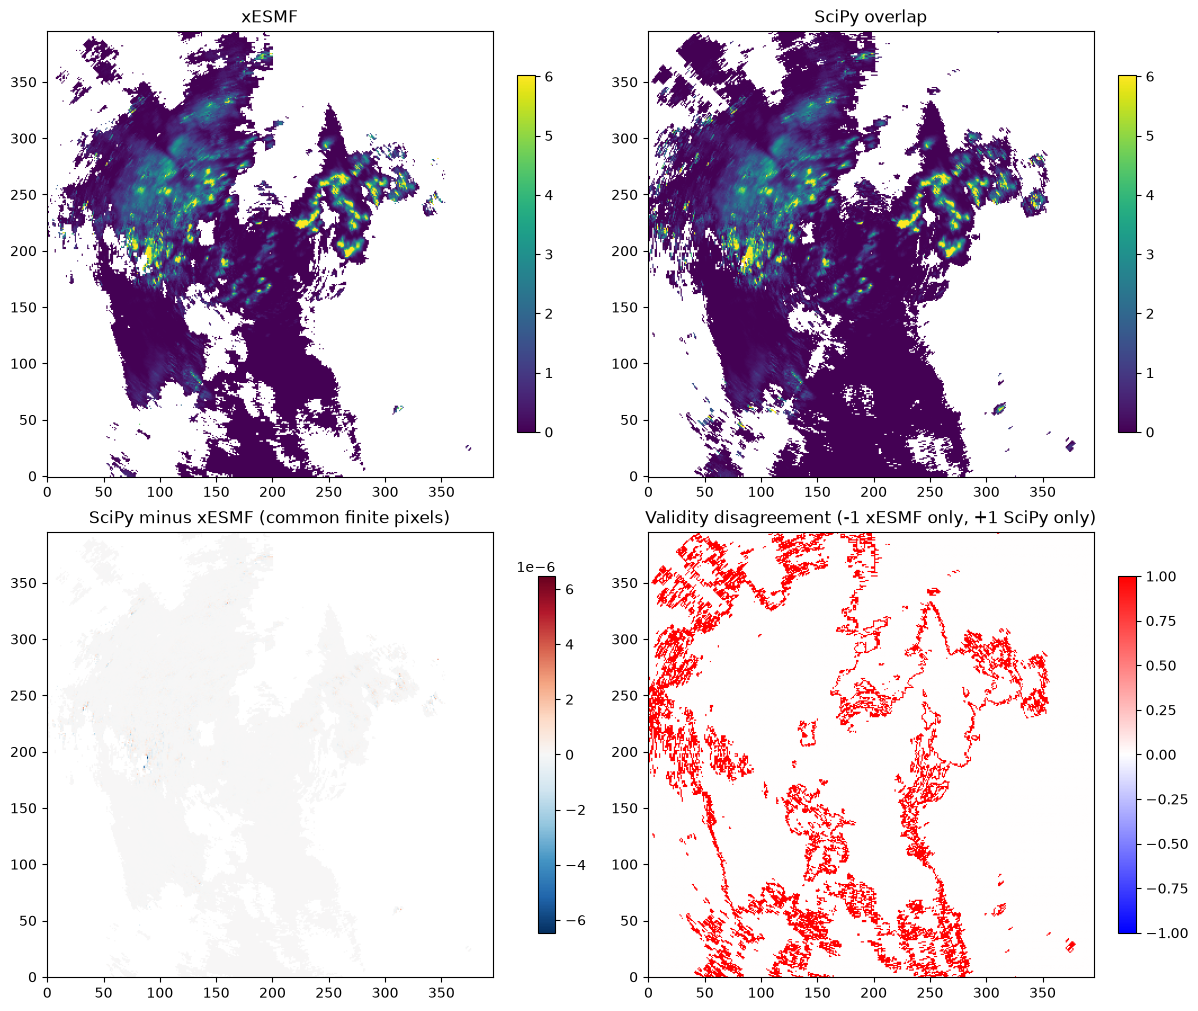

In [16]:
PRODUCT_TO_PLOT = '6h'
FILE_INDEX = 100

items = pairs.get(PRODUCT_TO_PLOT, [])
if not items:
    print('No matched files for', PRODUCT_TO_PLOT)
else:
    rel, pa, pb = items[FILE_INDEX]
    print('Plotting:', rel)
    with xr.open_dataset(pa) as dsa, xr.open_dataset(pb) as dsb:
        a = dsa[VAR].squeeze(drop=True).load()
        b = dsb[VAR].transpose(*dsa[VAR].dims).squeeze(drop=True).load()
    if a.ndim != 2 or b.ndim != 2 or a.shape != b.shape:
        print('Expected matching 2D fields after squeezing; got', a.shape, b.shape)
    else:
        av = np.asarray(a.values, float)
        bv = np.asarray(b.values, float)
        both = np.isfinite(av) & np.isfinite(bv)
        delta = np.where(both, bv-av, np.nan)
        mask_diff = np.isfinite(bv).astype(int) - np.isfinite(av).astype(int)
        valid_values = np.concatenate([av[np.isfinite(av)], bv[np.isfinite(bv)]])
        vmax = np.percentile(valid_values, 99) if valid_values.size else 1
        vmax = max(vmax, 1e-12)
        dmax = np.nanmax(np.abs(delta)) if np.isfinite(delta).any() else 1
        dmax = max(dmax, 1e-12)
        fig, axs = plt.subplots(2, 2, figsize=(12, 10), constrained_layout=True)
        for ax, arr, title, kw in [
            (axs[0,0], av, 'xESMF', dict(vmin=0, vmax=vmax, cmap='viridis')),
            (axs[0,1], bv, 'SciPy overlap', dict(vmin=0, vmax=vmax, cmap='viridis')),
            (axs[1,0], delta, 'SciPy minus xESMF (common finite pixels)', dict(vmin=-dmax, vmax=dmax, cmap='RdBu_r')),
            (axs[1,1], mask_diff, 'Validity disagreement (-1 xESMF only, +1 SciPy only)', dict(vmin=-1, vmax=1, cmap='bwr'))]:
            im = ax.imshow(arr, origin='lower', **kw)
            ax.set_title(title)
            fig.colorbar(im, ax=ax, shrink=.8)
        plt.show()


## 5. Rainfall histograms for the selected file

Zero rainfall is counted but excluded from the positive-only histograms. Both methods use the same histogram bins.

          xESMF  SciPy
finite    57717  76740
zero      20841  37801
positive  36876  38939


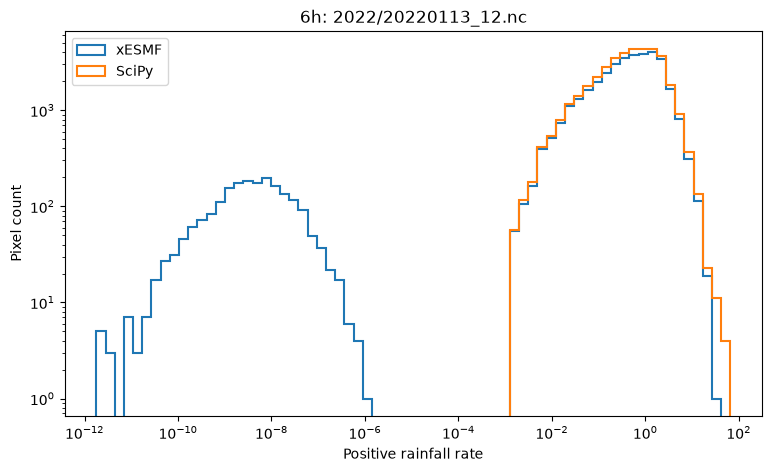

In [17]:
if items and a.ndim == 2 and b.ndim == 2 and a.shape == b.shape:
    aa = av[np.isfinite(av)]
    bb = bv[np.isfinite(bv)]
    print(pd.DataFrame({'xESMF': [len(aa), int((aa==0).sum()), int((aa>0).sum())],
                        'SciPy': [len(bb), int((bb==0).sum()), int((bb>0).sum())]},
                       index=['finite','zero','positive']))
    pos_a = aa[aa>0]
    pos_b = bb[bb>0]
    if len(pos_a) and len(pos_b):
        allpos = np.concatenate([pos_a, pos_b])
        lo, hi = allpos.min(), allpos.max()
        bins = np.logspace(np.log10(lo)-.01, np.log10(hi)+.01, 70) if hi>lo else np.array([lo*.9,hi*1.1])
        fig, ax = plt.subplots(figsize=(9,5))
        ax.hist(pos_a, bins=bins, histtype='step', linewidth=1.5, label='xESMF')
        ax.hist(pos_b, bins=bins, histtype='step', linewidth=1.5, label='SciPy')
        ax.set(xscale='log', yscale='log', xlabel='Positive rainfall rate', ylabel='Pixel count', title=f'{PRODUCT_TO_PLOT}: {rel}')
        ax.legend(); plt.show()
    else:
        print('No positive values in one or both fields; histogram skipped.')


## 6. Interpretation

- **`only_xesmf` / `only_scipy`** quantify different NaN masks. A small MAE on shared valid pixels can hide large coverage differences.
- **`mean_bias`** is SciPy minus xESMF on cells valid in both; **`pct_close`** is the percentage satisfying your chosen tolerances.
- Compare 6h and 24h separately. Small 6h differences can accumulate or change through missing-data-aware daily means.
- Differences may be scientifically expected because the SciPy method conserves **projected Cartesian** overlap areas whereas xESMF conservative regridding uses geographical cell geometry.
- **Do not interpret raw pixel sums as conservation tests.** For conservation, compare area-integrated rainfall over a common domain against the original source field, using appropriate cell areas and coverage. These processed outputs alone cannot establish that.
- If every difference is zero, verify the two folders really contain independently generated outputs and that their input data and grid metadata are the intended ones.
